# RetailPulse — Sales Performance Analysis

## Objective
Analyze retail sales performance to identify revenue trends,
top-performing products, and key geographic markets.

## Tools
Python, Pandas, NumPy, Matplotlib, Seaborn

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

print("Libraries imported successfully!")

Libraries imported successfully!


In [2]:
from pathlib import Path

DATA_PATH = Path("../data/processed/cleaned_transactions.csv")

sales = pd.read_csv(DATA_PATH)

sales["InvoiceDate"] = pd.to_datetime(sales["InvoiceDate"])

print("Dataset shape:", sales.shape)

sales.head()

Dataset shape: (524878, 9)


C:\Users\Swami-Anand\AppData\Local\Temp\ipykernel_26656\317429861.py:5: DtypeWarning: Columns (0: InvoiceNo) have mixed types. Specify dtype option on import or set low_memory=False.
  sales = pd.read_csv(DATA_PATH)


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,Revenue
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom,15.30
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom,22.00
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34


In [3]:
total_revenue = sales["Revenue"].sum()

total_orders = sales["InvoiceNo"].nunique()

total_customers = sales["CustomerID"].nunique()

total_units = sales["Quantity"].sum()

average_order_value = total_revenue / total_orders

print("RETAILPULSE SALES PERFORMANCE")
print("-" * 40)
print(f"Total Revenue: £{total_revenue:,.2f}")
print(f"Total Orders: {total_orders:,}")
print(f"Total Customers: {total_customers:,}")
print(f"Units Sold: {total_units:,}")
print(f"Average Order Value: £{average_order_value:,.2f}")

RETAILPULSE SALES PERFORMANCE
----------------------------------------
Total Revenue: £10,642,110.80
Total Orders: 19,962
Total Customers: 4,338
Units Sold: 5,572,420
Average Order Value: £533.12


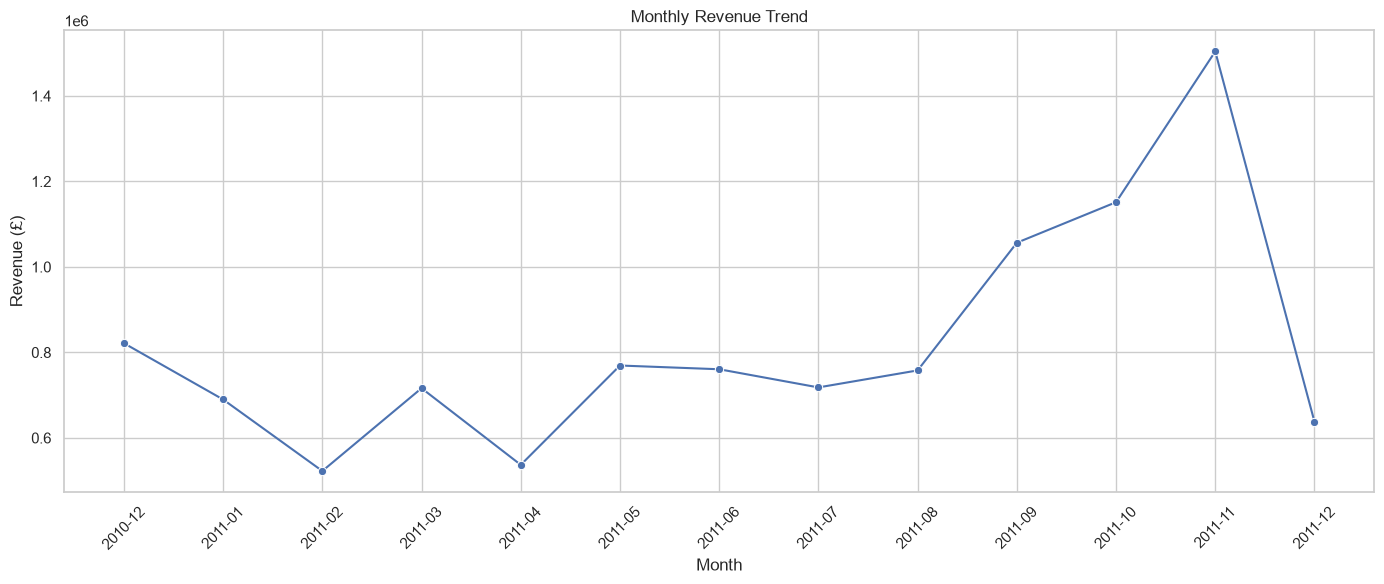

In [4]:
sales["YearMonth"] = (
    sales["InvoiceDate"].dt.to_period("M").astype(str)
)

monthly_revenue = (
    sales.groupby("YearMonth")["Revenue"]
    .sum()
    .reset_index()
)

plt.figure(figsize=(14, 6))

sns.lineplot(
    data=monthly_revenue,
    x="YearMonth",
    y="Revenue",
    marker="o"
)

plt.title("Monthly Revenue Trend")
plt.xlabel("Month")
plt.ylabel("Revenue (£)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

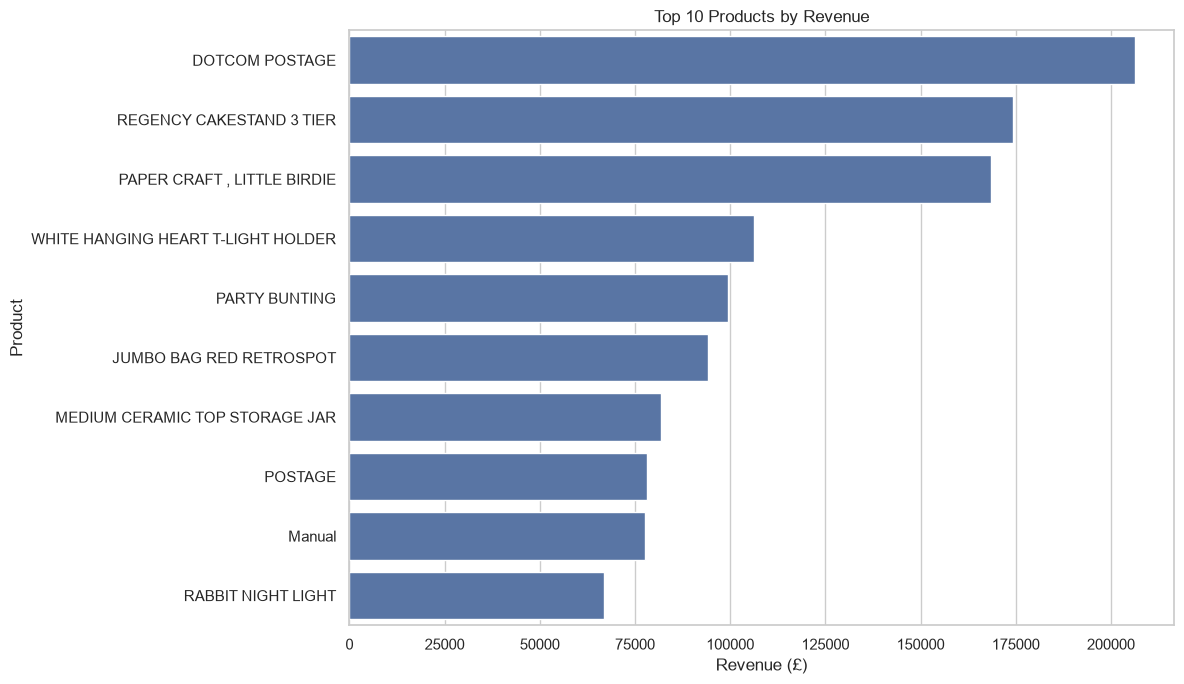

,Description,Revenue
0,DOTCOM POSTAGE,206248.77
1,REGENCY CAKESTAND 3 TIER,174156.54
2,"PAPER CRAFT , LITTLE BIRDIE",168469.60
3,WHITE HANGING HEART T-LIGHT HOLDER,106236.72
4,PARTY BUNTING,99445.23
5,JUMBO BAG RED RETROSPOT,94159.81
6,MEDIUM CERAMIC TOP STORAGE JAR,81700.92
7,POSTAGE,78101.88
8,Manual,77752.82
9,RABBIT NIGHT LIGHT,66870.03


In [5]:
top_products = (
    sales.groupby("Description")["Revenue"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
    .reset_index()
)

plt.figure(figsize=(12, 7))

sns.barplot(
    data=top_products,
    x="Revenue",
    y="Description"
)

plt.title("Top 10 Products by Revenue")
plt.xlabel("Revenue (£)")
plt.ylabel("Product")

plt.tight_layout()
plt.show()

top_products

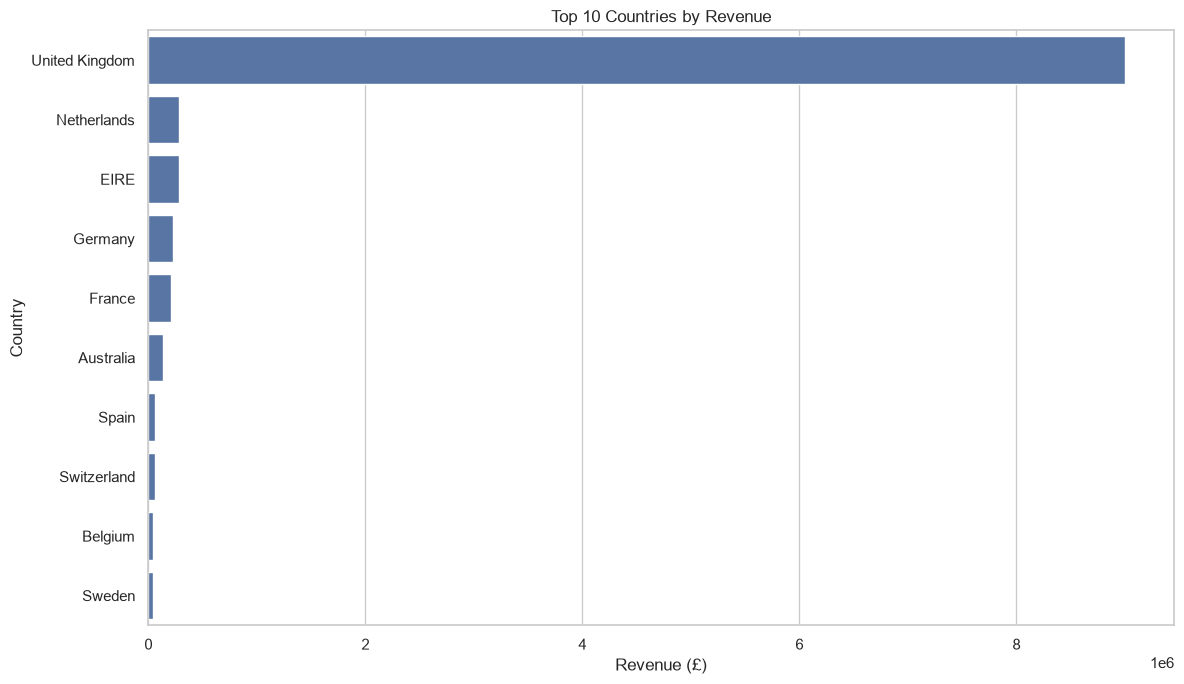

,Country,Revenue
0,United Kingdom,9001744.094
1,Netherlands,285446.340
2,EIRE,283140.520
3,Germany,228678.400
4,France,209625.370
5,Australia,138453.810
6,Spain,61558.560
7,Switzerland,57067.600
8,Belgium,41196.340
9,Sweden,38367.830


In [6]:
country_revenue = (
    sales.groupby("Country")["Revenue"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
    .reset_index()
)

plt.figure(figsize=(12, 7))

sns.barplot(
    data=country_revenue,
    x="Revenue",
    y="Country"
)

plt.title("Top 10 Countries by Revenue")
plt.xlabel("Revenue (£)")
plt.ylabel("Country")

plt.tight_layout()
plt.show()

country_revenue

In [7]:
monthly_revenue["MoM_Growth_Percentage"] = (
    monthly_revenue["Revenue"]
    .pct_change()
    .mul(100)
)

monthly_revenue

,YearMonth,Revenue,MoM_Growth_Percentage
0,2010-12,821452.730,NaN
1,2011-01,689811.610,-16.025404
2,2011-02,522545.560,-24.248077
3,2011-03,716215.260,37.062740
4,2011-04,536968.491,-25.026941
5,2011-05,769296.610,43.266620
6,2011-06,760547.010,-1.137351
7,2011-07,718076.121,-5.584256
8,2011-08,757841.380,5.537750
9,2011-09,1056435.192,39.400568


In [8]:
country_contribution = (
    sales.groupby("Country")["Revenue"]
    .sum()
    .reset_index()
)

country_contribution["Revenue_Percentage"] = (
    country_contribution["Revenue"]
    / country_contribution["Revenue"].sum()
    * 100
)

country_contribution = country_contribution.sort_values(
    "Revenue",
    ascending=False
)

country_contribution.head(10)

,Country,Revenue,Revenue_Percentage
36,United Kingdom,9001744.094,84.586078
24,Netherlands,285446.340,2.682234
10,EIRE,283140.520,2.660567
14,Germany,228678.400,2.148807
13,France,209625.370,1.969772
0,Australia,138453.810,1.301000
31,Spain,61558.560,0.578443
33,Switzerland,57067.600,0.536243
3,Belgium,41196.340,0.387107
32,Sweden,38367.830,0.360528


In [9]:
from pathlib import Path

report_dir = Path("../reports")
report_dir.mkdir(exist_ok=True)

monthly_revenue.to_csv(
    report_dir / "monthly_revenue_analysis.csv",
    index=False
)

top_products.to_csv(
    report_dir / "top_products_analysis.csv",
    index=False
)

country_revenue.to_csv(
    report_dir / "country_revenue_analysis.csv",
    index=False
)

print("Sales analysis reports exported successfully!")

Sales analysis reports exported successfully!
